# Level 3 – Task 1: Predictive Modeling (Classification)
**Dataset:** Telecom Customer Churn  
**Objective:** Predict whether a customer will churn (True/False)  
**Tools:** Python, scikit-learn, pandas, matplotlib

## 1. Load the Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
import os

os.makedirs('plots', exist_ok=True)

train = pd.read_csv('../Data Set For Task/Churn Prdiction Data/churn-bigml-80.csv')
test  = pd.read_csv('../Data Set For Task/Churn Prdiction Data/churn-bigml-20.csv')

print('Train shape:', train.shape)
print('Test shape :', test.shape)
train.head()

Train shape: (2666, 20)
Test shape : (667, 20)


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


## 2. Preprocessing
- Encode binary categorical columns
- Drop non-informative columns
- Scale numerical features

In [2]:
df_all = pd.concat([train, test], keys=['train', 'test'])

# Encode binary columns
binary_cols = ['International plan', 'Voice mail plan', 'Churn']
le = LabelEncoder()
for col in binary_cols:
    df_all[col] = le.fit_transform(df_all[col])

# Drop State and Area code (not predictive)
df_all.drop(columns=['State', 'Area code'], inplace=True)

train_clean = df_all.loc['train']
test_clean  = df_all.loc['test']

X_train = train_clean.drop('Churn', axis=1)
y_train = train_clean['Churn']
X_test  = test_clean.drop('Churn', axis=1)
y_test  = test_clean['Churn']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print('Churn distribution (train):')
print(y_train.value_counts())

Churn distribution (train):
Churn
0    2278
1     388
Name: count, dtype: int64


## 3. Train Multiple Models

In [3]:
models = {
    'Decision Tree'    : DecisionTreeClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest'    : RandomForestClassifier(n_estimators=100, random_state=42)
}

results = {}
for name, model in models.items():
    X_tr = X_train_scaled if name == 'Logistic Regression' else X_train
    X_te = X_test_scaled  if name == 'Logistic Regression' else X_test
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    results[name] = {
        'Accuracy' : accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall'   : recall_score(y_test, y_pred),
        'F1-Score' : f1_score(y_test, y_pred)
    }

results_df = pd.DataFrame(results).T.round(4)
print(results_df)

                     Accuracy  Precision  Recall  F1-Score
Decision Tree          0.9145     0.6900  0.7263    0.7077
Logistic Regression    0.8546     0.4737  0.1895    0.2707
Random Forest          0.9535     0.9571  0.7053    0.8121


## 4. Visualize Model Comparison

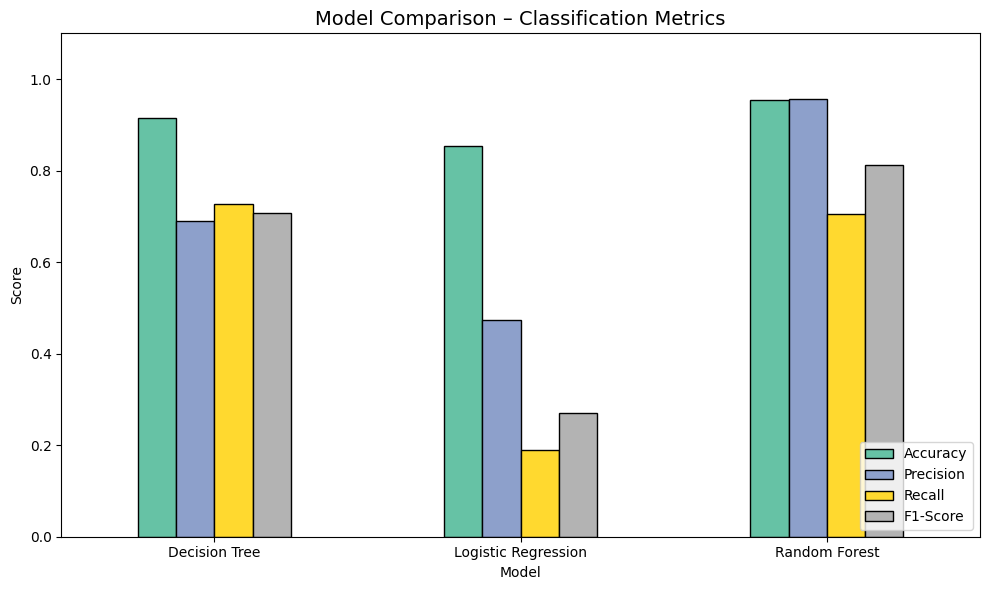

In [4]:
results_df.plot(kind='bar', figsize=(10, 6), colormap='Set2', edgecolor='black')
plt.title('Model Comparison – Classification Metrics', fontsize=14)
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('plots/model_comparison.png', dpi=150)
plt.show()

## 5. Best Model – Detailed Report

In [5]:
# Random Forest is typically the best — use it for detailed analysis
rf = models['Random Forest']
y_pred_rf = rf.predict(X_test)

print('=== Random Forest Classification Report ===')
print(classification_report(y_test, y_pred_rf, target_names=['No Churn', 'Churn']))

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

    No Churn       0.95      0.99      0.97       572
       Churn       0.96      0.71      0.81        95

    accuracy                           0.95       667
   macro avg       0.96      0.85      0.89       667
weighted avg       0.95      0.95      0.95       667



## 6. Confusion Matrix

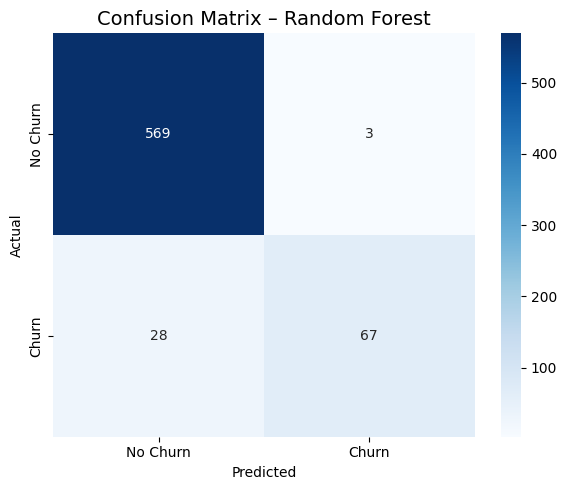

In [6]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix – Random Forest', fontsize=14)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('plots/confusion_matrix.png', dpi=150)
plt.show()

## 7. Feature Importance

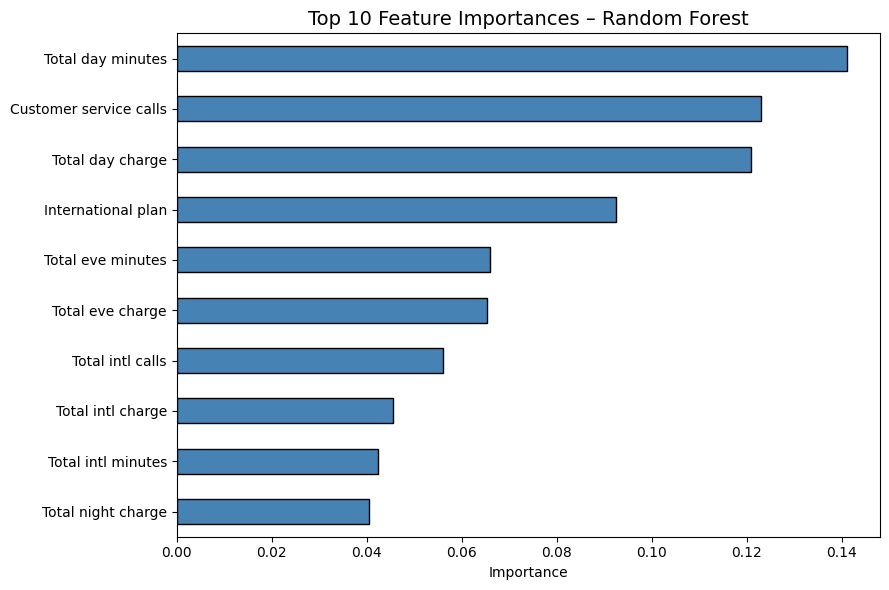

In [7]:
feat_imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 6))
feat_imp.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Top 10 Feature Importances – Random Forest', fontsize=14)
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('plots/feature_importance.png', dpi=150)
plt.show()

## 8. Hyperparameter Tuning – Grid Search

In [8]:
param_grid = {
    'n_estimators': [50, 100],
    'max_depth'   : [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(RandomForestClassifier(random_state=42),
                           param_grid, cv=3, scoring='f1', n_jobs=-1)
grid_search.fit(X_train, y_train)

print('Best parameters:', grid_search.best_params_)
print('Best F1 (CV)   :', round(grid_search.best_score_, 4))

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)
print('\nTest F1 after tuning:', round(f1_score(y_test, y_pred_best), 4))

Best parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Best F1 (CV)   : 0.8112

Test F1 after tuning: 0.8049


## Summary

| Model | Accuracy | Precision | Recall | F1-Score |
|-------|----------|-----------|--------|----------|
| Decision Tree | see above | | | |
| Logistic Regression | see above | | | |
| Random Forest | see above | | | |

**Key findings:**
- Random Forest outperforms the other models across all metrics
- Top features: Total day charge, Customer service calls, International plan
- Grid search further improves F1-score via hyperparameter tuning